# EDA · Análogos terrestres de la Luna (v0)
**NASA Space Apps Challenge 2026** · Complemento del EDA de Marte (`EDA_analogos_v1.3.ipynb`).

**Idea:** en la Luna no hay clima ni vegetación; un análogo lunar se define por la **roca expuesta**, sobre todo basáltica
(como los "mares" lunares): coladas de lava, tubos volcánicos, conos de ceniza. Buscamos **superficies desnudas pobres en cuarzo**
con la emisividad térmica (CAMEL) y la vegetación (VIIRS NDVI), ambas a 0,05° (~5 km).

**Preguntas**
1. ¿Distingue la emisividad térmica los basaltos de las arenas de cuarzo a 5 km?
2. ¿Qué filtros hacen falta (vegetación estacional, nieve, carbonatos)?
3. ¿Recupera el perfil los análogos lunares reconocidos sin decirle dónde están, y qué regiones nuevas propone?

**Fuentes de datos**
| Producto | Uso | Resolución |
|---|---|---|
| CAMEL Emissivity Climatology `CAM5K30EMCLIM` v003 (2003-2021) | emisividad en 13 longitudes de onda | 0,05° |
| VIIRS `VNP13C2` v002 (2023) | NDVI mensual | 0,05° |

**Índices** (adaptados de Ninomiya, sobre emisividades en lugar de radiancias ASTER):
`MI = e9.1/e10.6` (alto = pobre en cuarzo / máfico) · `QI = e8.6²/(e8.3·e9.1)` (alto = cuarzo) · `CI = e10.6/e11.3` (alto = carbonatos).

**Uso:** *Ejecutar todas*. Todo se guarda en Drive y se reutiliza. Solo necesita Earthdata si falta algún archivo en `03_datos/brutos`.

## 0. Instalación

In [1]:
!pip install -q earthaccess geopy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


## 1. Configuración

In [2]:
import os, json, shutil, datetime, logging, time
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage
import earthaccess
from IPython.display import HTML, display
from google.colab import drive, userdata

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
BRUTOS     = f"{BASE}/03_datos/brutos"
PROCESADOS = f"{BASE}/03_datos/procesados"
CACHE_API  = f"{BASE}/03_datos/cache_api"
VERSION_LUNA = "luna_v0"
RES_LUNA   = f"{BASE}/04_resultados/{VERSION_LUNA}"
TMP = "/content/tmp"
for d in (BRUTOS, PROCESADOS, CACHE_API, RES_LUNA, TMP):
    os.makedirs(d, exist_ok=True)

os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
auth = earthaccess.login(strategy="environment")
print("Carpeta:", BASE, "| Earthdata:", auth.authenticated)

def existe(ruta, forzar=False):
    ok = os.path.exists(ruta) and not forzar
    print(("✔ desde Drive: " if ok else "⬇ calculando: ") + os.path.basename(ruta))
    return ok

def guardar_nc(obj, ruta, encoding=None):
    tmp = os.path.join(TMP, os.path.basename(ruta))
    obj.to_netcdf(tmp, encoding=encoding)
    shutil.copy2(tmp, ruta)
    os.remove(tmp)

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

ENC_IND = {v: {"dtype": "int16", "scale_factor": 1e-4, "_FillValue": -32768, "zlib": True}
           for v in ("MI", "QI", "CI", "nieve")}
ENC_NDVI = {"ndvi": {"dtype": "int16", "scale_factor": 1e-4, "_FillValue": -32768, "zlib": True}}

Mounted at /content/drive
Carpeta: /content/drive/MyDrive/Hackathon Nasa | Earthdata: True


## 2. Puntos de referencia
- **Análogos lunares con fuente** (validación): sitios usados por la NASA o la ESA como análogos lunares o para entrenar astronautas del programa Apollo.
- **Campos volcánicos de prueba**: grandes campos de lava en desiertos, sin fuente como análogo lunar; sirven para comprobar que el índice detecta basaltos.
- **Controles negativos**: arenas de cuarzo y ciudades. Deben puntuar bajo o quedar fuera del dominio.
Coordenadas aproximadas (centro de la zona de estudio).

In [3]:
ANALOGOS_LUNA = pd.DataFrame([
    # nombre, lat, lon, tipo, verificación, motivo, fuente
    ["Craters of the Moon, Idaho", 43.42, -113.52, "analogo_luna", "verificada",
     "Sistema volcánico basáltico con análogos de formaciones volcánicas lunares (FINESSE/BASALT)",
     "https://dsears.hosted.uark.edu/publications/pub%20by%20year/2017%20papers/Heldmann%20et%20al%202017%20-%20Analog%20research%20wrt%20the%20Moon%20(LEAG%20abs%205024).pdf"],
    ["Kīlauea, Hawái", 19.41, -155.28, "analogo_luna", "verificada",
     "Terreno basáltico con rasgos superficiales análogos a los lunares (FINESSE/BASALT)",
     "https://dsears.hosted.uark.edu/publications/pub%20by%20year/2017%20papers/Heldmann%20et%20al%202017%20-%20Analog%20research%20wrt%20the%20Moon%20(LEAG%20abs%205024).pdf"],
    ["Pinacate, Sonora", 31.77, -113.50, "analogo_luna", "verificada",
     "Entrenamiento geológico de astronautas Apollo (1965-1967)",
     "https://www.nasa.gov/wp-content/uploads/static/history/alsj/AstronautGeologyTraining.pdf"],
    ["Askja, Islandia", 65.03, -16.75, "analogo_luna", "verificada",
     "Entrenamiento geológico de astronautas Apollo (1965, 1967)",
     "https://www.nasa.gov/wp-content/uploads/static/history/alsj/AstronautGeologyTraining.pdf"],
    ["Lanzarote – Timanfaya", 29.00, -13.75, "analogo_luna", "verificada",
     "Entrenamiento ESA PANGAEA en entornos análogos de la Luna y Marte",
     "https://www.esa.int/ESA_Multimedia/Images/2021/03/Geological_training_in_terrestrial_Moon_and_Mars_analogue_environments"],
    ["Mauna Kea, Hawái", 19.82, -155.47, "analogo_luna", "pendiente",
     "Sede de pruebas de campo de ISRU para la Luna y Marte (2008, 2010)",
     "https://ntrs.nasa.gov/citations/20100021362"],
    ["Meteor Crater, Arizona", 35.03, -111.02, "impacto", "verificada",
     "Entrenamiento Apollo; cráter de impacto en rocas sedimentarias (no basáltico: no se espera que puntúe)",
     "https://www.nasa.gov/wp-content/uploads/static/history/alsj/AstronautGeologyTraining.pdf"],
    # Campos volcánicos de prueba (sin fuente como análogo lunar)
    ["Al Haruj, Libia", 27.25, 17.50, "volcanico_prueba", "", "", ""],
    ["Harrat Khaybar, Arabia Saudí", 25.75, 39.90, "volcanico_prueba", "", "", ""],
    ["Harrat Rahat, Arabia Saudí", 23.00, 39.80, "volcanico_prueba", "", "", ""],
    ["Hoggar – Atakor, Argelia", 23.30, 5.65, "volcanico_prueba", "", "", ""],
    ["Payún Matrú, Argentina", -36.42, -69.24, "volcanico_prueba", "", "", ""],
    ["Holuhraun, Islandia", 64.85, -16.83, "volcanico_prueba", "", "", ""],
    # Controles negativos
    ["Gran Erg Oriental (arena)", 30.50, 7.50, "control_arena", "", "", ""],
    ["Rub' al-Jali (arena)", 20.50, 50.50, "control_arena", "", "", ""],
    ["Taklamakán (arena)", 39.00, 83.00, "control_arena", "", "", ""],
    ["Mar de arena del Namib", -24.50, 15.20, "control_arena", "", "", ""],
    ["Algodones (arena)", 32.95, -115.05, "control_arena", "", "", ""],
    ["Madrid", 40.40, -3.70, "control_ciudad", "", "", ""],
    ["París", 48.85, 2.35, "control_ciudad", "", "", ""],
    ["Moscú", 55.75, 37.60, "control_ciudad", "", "", ""],
    ["Manaos", -3.10, -60.00, "control_ciudad", "", "", ""],
    ["Bombay", 19.10, 72.90, "control_ciudad", "", "", ""],
    ["Sídney", -33.90, 151.20, "control_ciudad", "", "", ""],
], columns=["nombre", "lat", "lon", "tipo", "verificacion", "motivo", "fuente"])
ANALOGOS_LUNA.to_csv(f"{RES_LUNA}/puntos_referencia_luna.csv", index=False)
ANALOGOS_LUNA.groupby("tipo").size()

,0
tipo,
analogo_luna,6
control_arena,5
control_ciudad,6
impacto,1
volcanico_prueba,6


## 3. Datos
### 3.1 CAMEL: descarga directa (julio y enero)
El buscador de la NASA (CMR) falló con estas colecciones en octubre de 2026, así que se descarga por URL directa con la sesión de Earthdata.
Se usa **julio en el hemisferio norte y enero en el sur** (verano de cada hemisferio, menos nieve).

In [4]:
URL_CAMEL = ("https://data.lpdaac.earthdatacloud.nasa.gov/{bucket}/CAM5K30EMCLIM.003/"
             "CAM5K30EMCLIM_emis_climatology_{m:02d}Month_V003/CAM5K30EMCLIM_emis_climatology_{m:02d}Month_V003.nc")

def descargar_camel(m):
    nombre = f"CAM5K30EMCLIM_emis_climatology_{m:02d}Month_V003.nc"
    destino = f"{BRUTOS}/{nombre}"
    if existe(destino):
        return destino
    sesion = earthaccess.get_requests_https_session()
    for bucket in ("lp-prod-protected", "lp-prod-public"):
        url = URL_CAMEL.format(bucket=bucket, m=m)
        r = sesion.get(url, stream=True, timeout=180)
        cabecera = next(r.iter_content(8), b"") if r.status_code == 200 else b""
        if cabecera.startswith(b"\x89HDF"):
            tmp = f"{TMP}/{nombre}"
            with open(tmp, "wb") as f:
                f.write(cabecera)
                for trozo in r.iter_content(1 << 20):
                    f.write(trozo)
            shutil.copy2(tmp, destino); os.remove(tmp)
            print(f"   ✔ descargado de {bucket}: {os.path.getsize(destino)/1e6:.0f} MB")
            return destino
        print(f"   · {bucket}: HTTP {r.status_code}")
    raise RuntimeError("Descárgalo en el navegador (sesión de Earthdata iniciada) y súbelo a 03_datos/brutos:\n"
                       + URL_CAMEL.format(bucket="lp-prod-protected", m=m))

RUTAS_CAMEL = {m: descargar_camel(m) for m in (7, 1)}
camel_jul = xr.open_dataset(RUTAS_CAMEL[7], engine="h5netcdf")
WL = np.ravel(camel_jul["wavelength"].values)
print("Longitudes de onda (µm):", np.round(WL, 2))

✔ desde Drive: CAM5K30EMCLIM_emis_climatology_07Month_V003.nc
✔ desde Drive: CAM5K30EMCLIM_emis_climatology_01Month_V003.nc
Longitudes de onda (µm): [ 3.6  4.3  5.   5.8  7.6  8.3  8.6  9.1 10.6 10.8 11.3 12.1 14.3]


### 3.2 Índices de emisividad (verano de cada hemisferio)

In [5]:
def indices_camel(m):
    ruta = f"{PROCESADOS}/emisividad_indices_camel_{m:02d}.nc"
    if existe(ruta):
        return xr.open_dataset(ruta).load()
    c = xr.open_dataset(RUTAS_CAMEL[m], engine="h5netcdf")
    wl = np.ravel(c["wavelength"].values)
    banda = lambda x: c["camel_emis"].isel(spectra=int(np.abs(wl - x).argmin())).astype("float32").load()
    e83, e86, e91, e106, e113 = (banda(x) for x in (8.3, 8.6, 9.1, 10.6, 11.3))
    out = xr.Dataset({"MI": e91 / e106, "QI": e86**2 / (e83 * e91), "CI": e106 / e113,
                      "nieve": c["snow_fraction_average"].astype("float32").load()})
    out = out.rename({"latitude": "lat", "longitude": "lon"}).sortby("lat")
    out.attrs = {"fuente": f"CAMEL climatología mes {m:02d}, 2003-2021 (CAM5K30EMCLIM v003)"}
    guardar_nc(out, ruta, ENC_IND)
    return out

ruta_verano = f"{PROCESADOS}/emisividad_indices_camel_verano.nc"
if existe(ruta_verano):
    emis = xr.open_dataset(ruta_verano).load()
else:
    jul, ene = indices_camel(7), indices_camel(1)
    ene = ene.assign_coords(lat=jul.lat.values, lon=jul.lon.values)
    sur = jul.lat < 0
    emis = xr.Dataset({v: xr.where(sur, ene[v], jul[v]).transpose("lat", "lon") for v in ("MI", "QI", "CI", "nieve")})
    emis.attrs = {"fuente": "CAMEL climatología 2003-2021: julio al norte del ecuador, enero al sur",
                  "MI": "e9.1/e10.6", "QI": "e8.6^2/(e8.3*e9.1)", "CI": "e10.6/e11.3"}
    guardar_nc(emis, ruta_verano, ENC_IND)
LATS, LONS = emis.lat.values, emis.lon.values
DLAT, DLON = abs(LATS[1] - LATS[0]), abs(LONS[1] - LONS[0])
print(dict(emis.sizes), f"| celda {DLAT:.3f}° × {DLON:.3f}°")

✔ desde Drive: emisividad_indices_camel_verano.nc
{'lat': 3600, 'lon': 7200} | celda 0.050° × 0.050°


### 3.3 NDVI 2023: máximo y **mediana** anual
El máximo descarta campos de lava con vegetación efímera tras las lluvias de invierno (Harrat Rahat, Pinacate);
para la Luna importa que la roca esté expuesta la mayor parte del año, así que se usa la mediana.
VIIRS guarda las coordenadas en la esquina de la celda y CAMEL en el centro: se comprueba que es la misma rejilla.

In [6]:
def leer_ndvi_mes(m):
    ruta = f"{BRUTOS}/ndvi_2023_{m:02d}.nc"
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"Falta {ruta}: ejecuta la sección 3.7 del EDA de Marte para descargar el NDVI mensual.")
    return xr.open_dataarray(ruta)

def alinear(da):
    """Misma rejilla con otra convención (esquina/centro) -> coordenadas de CAMEL."""
    mismo = da.sizes["lat"] == len(LATS) and da.sizes["lon"] == len(LONS)
    dlat = np.abs(da.lat.values - LATS).max() if mismo else np.inf
    dlon = np.abs(da.lon.values - LONS).max() if mismo else np.inf
    if dlat <= 0.51 * DLAT and dlon <= 0.51 * DLON:
        return da.assign_coords(lat=LATS, lon=LONS)
    print(f"⚠ rejillas distintas (dif. lat {dlat:.4f}, lon {dlon:.4f}): asigno el píxel más cercano")
    return da.sel(lat=LATS, lon=LONS, method="nearest").assign_coords(lat=LATS, lon=LONS)

def ndvi_resumen(nombre, funcion):
    ruta = f"{PROCESADOS}/ndvi_{nombre}_2023_005.nc"
    if existe(ruta):
        return xr.open_dataarray(ruta).load()
    meses = [leer_ndvi_mes(m) for m in range(1, 13)]
    out = np.full(meses[0].shape, np.nan, dtype="float32")
    for i0 in range(0, out.shape[0], 600):                     # por bandas de latitud (RAM)
        pila = np.stack([m.values[i0:i0 + 600].astype("float32") for m in meses])
        out[i0:i0 + 600] = funcion(pila, axis=0)
    da = xr.DataArray(out, dims=("lat", "lon"), coords={"lat": meses[0].lat, "lon": meses[0].lon}, name="ndvi")
    da.attrs = {"long_name": f"NDVI {nombre} mensual 2023 (VIIRS VNP13C2 v002, 0.05°)"}
    guardar_nc(da.to_dataset(), ruta, ENC_NDVI)
    return da

ndvi_max = alinear(ndvi_resumen("max", np.nanmax))
ndvi_med = alinear(ndvi_resumen("mediana", np.nanmedian))
print("NDVI máximo:", float(np.nanmin(ndvi_max)), "a", float(np.nanmax(ndvi_max)),
      "| NDVI mediano:", float(np.nanmin(ndvi_med)), "a", float(np.nanmax(ndvi_med)))

✔ desde Drive: ndvi_max_2023_005.nc
⬇ calculando: ndvi_mediana_2023_005.nc


/tmp/ipykernel_2340/2072652198.py:25: RuntimeWarning: All-NaN slice encountered
  out[i0:i0 + 600] = funcion(pila, axis=0)


NDVI máximo: -0.7033 a 0.9971000000000001 | NDVI mediano: -0.7975500226020813 a 0.9212000370025635


## 4. Exploración de la emisividad
### 4.1 Espectros en los puntos de referencia
Las arenas de cuarzo muestran una caída de emisividad entre 8 y 9,5 µm (banda *reststrahlen* del cuarzo);
los basaltos y la vegetación tienen espectros casi planos.

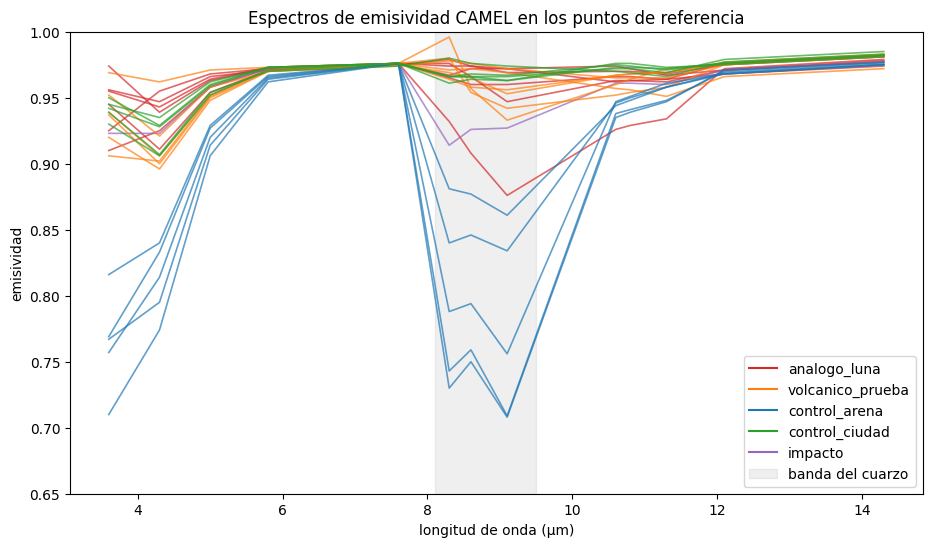

In [7]:
def celda(la, lo):
    return int(np.abs(LATS - la).argmin()), int(np.abs(LONS - lo).argmin())

camel_ene = xr.open_dataset(RUTAS_CAMEL[1], engine="h5netcdf")
def espectro(la, lo):
    c = camel_jul if la >= 0 else camel_ene
    lat_c, lon_c = np.ravel(c["latitude"].values), np.ravel(c["longitude"].values)
    e = c["camel_emis"].isel(latitude=int(np.abs(lat_c - la).argmin()), longitude=int(np.abs(lon_c - lo).argmin()))
    return np.asarray(e.values, dtype=float)

colores = {"analogo_luna": "tab:red", "volcanico_prueba": "tab:orange", "control_arena": "tab:blue",
           "control_ciudad": "tab:green", "impacto": "tab:purple"}
fig, ax = plt.subplots(figsize=(11, 6))
for r in ANALOGOS_LUNA.itertuples():
    ax.plot(WL, espectro(r.lat, r.lon), color=colores[r.tipo], alpha=0.7, lw=1.2)
for tipo, col in colores.items():
    ax.plot([], [], color=col, label=tipo)
ax.axvspan(8.1, 9.5, color="grey", alpha=0.12, label="banda del cuarzo")
ax.set_xlabel("longitud de onda (µm)"); ax.set_ylabel("emisividad"); ax.set_ylim(0.65, 1.0); ax.legend()
ax.set_title("Espectros de emisividad CAMEL en los puntos de referencia"); plt.show()

### 4.2 Valores en los puntos de referencia

In [8]:
UMBRAL_DESNUDO, UMBRAL_NIEVE, UMBRAL_CI = 0.15, 0.10, 1.008

def tabla_puntos():
    filas = []
    for r in ANALOGOS_LUNA.itertuples():
        i, j = celda(r.lat, r.lon)
        filas.append({"nombre": r.nombre, "tipo": r.tipo,
                      "NDVI_max": float(ndvi_max.values[i, j]), "NDVI_mediana": float(ndvi_med.values[i, j]),
                      "nieve": float(emis.nieve.values[i, j]), "MI": float(emis.MI.values[i, j]),
                      "QI": float(emis.QI.values[i, j]), "CI": float(emis.CI.values[i, j])})
    return pd.DataFrame(filas).round(3)

puntos = tabla_puntos()
display(puntos)
print(puntos.groupby("tipo")[["MI", "QI", "CI", "NDVI_mediana"]].median().round(3))

,nombre,tipo,NDVI_max,NDVI_mediana,nieve,MI,QI,CI
0,"Craters of the Moon, Idaho",analogo_luna,0.311,0.271,0.01,0.999,1.000,1.002
1,"Kīlauea, Hawái",analogo_luna,0.536,0.480,0.00,0.983,1.010,1.001
2,"Pinacate, Sonora",analogo_luna,0.256,0.180,0.00,0.994,0.995,1.002
3,"Askja, Islandia",analogo_luna,0.020,-0.034,0.09,0.998,1.005,1.007
4,Lanzarote – Timanfaya,analogo_luna,0.153,0.117,0.00,1.018,1.000,0.998
5,"Mauna Kea, Hawái",analogo_luna,0.066,0.061,0.00,0.946,1.010,0.991
6,"Meteor Crater, Arizona",impacto,0.184,0.164,0.00,0.965,1.012,1.001
7,"Al Haruj, Libia",volcanico_prueba,0.103,0.097,0.00,0.988,1.008,0.996
8,"Harrat Khaybar, Arabia Saudí",volcanico_prueba,0.126,0.077,0.00,1.007,1.002,1.000
9,"Harrat Rahat, Arabia Saudí",volcanico_prueba,0.255,0.133,0.00,0.989,0.996,0.998


                     MI     QI     CI  NDVI_mediana
tipo                                               
analogo_luna      0.996  1.002  1.002         0.148
control_arena     0.798  1.058  0.987         0.098
control_ciudad    0.993  1.003  1.003         0.324
impacto           0.965  1.012  1.001         0.164
volcanico_prueba  0.990  0.999  0.997         0.086


### 4.3 NDVI mensual en campos de lava
¿Vegetación estacional real o efecto de la superficie oscura? Una serie plana en ~0,10 es suelo desnudo (Al Haruj, Atacama).

In [9]:
SERIE_NDVI = {"Harrat Rahat": (23.00, 39.80), "Pinacate": (31.77, -113.50), "Lanzarote – Timanfaya": (29.00, -13.75),
              "Payún Matrú": (-36.42, -69.24), "Craters of the Moon": (43.42, -113.52),
              "Al Haruj (desnudo)": (27.25, 17.50), "Atacama (desnudo)": (-24.10, -70.00)}
series = {nom: [] for nom in SERIE_NDVI}
for m in range(1, 13):                                   # abre cada mes una sola vez
    with leer_ndvi_mes(m) as da:
        for nom, (la, lo) in SERIE_NDVI.items():
            series[nom].append(round(float(da.sel(lat=la, lon=lo, method="nearest")), 2))
pd.DataFrame(series, index=range(1, 13)).T

,1,2,3,4,5,6,7,8,9,10,11,12
Harrat Rahat,0.29,0.26,0.18,0.13,0.12,0.11,0.10,0.10,0.10,0.10,0.14,0.19
Pinacate,0.18,0.18,0.19,0.16,0.15,0.14,0.14,0.14,0.16,0.16,0.15,0.15
Lanzarote – Timanfaya,0.15,0.15,0.14,0.13,0.11,0.12,0.12,0.10,0.11,0.12,0.12,0.11
Payún Matrú,0.07,0.07,0.07,0.07,0.03,0.03,-0.03,-0.03,-0.03,-0.01,0.01,0.07
Craters of the Moon,-0.03,-0.03,-0.03,0.20,0.28,0.37,0.31,0.29,0.28,0.29,0.31,0.29
Al Haruj (desnudo),0.10,0.10,0.10,0.09,0.09,0.09,0.09,0.09,0.09,0.10,0.10,0.10
Atacama (desnudo),0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10


### 4.4 Carbonatos: CI en las celdas pobres en cuarzo
Las calizas también tienen MI alto. Su emisividad baja a 11,3 µm, así que su CI es alto.
Se excluyen las celdas con `CI > 1,008` (por encima del volcánico más alto y en torno al p90 de las celdas con MI alto).

Celdas desnudas (NDVI mediano): 1,063,762 | con MI ≥ p90 (1.001): 114,545
CI en celdas con MI alto: p10 1.000 · mediana 1.002 · p90 1.006 | volcánicos y análogos: 0.988–1.007
Se excluirían por carbonato (CI > 1.008): 4.8 % de las celdas con MI alto


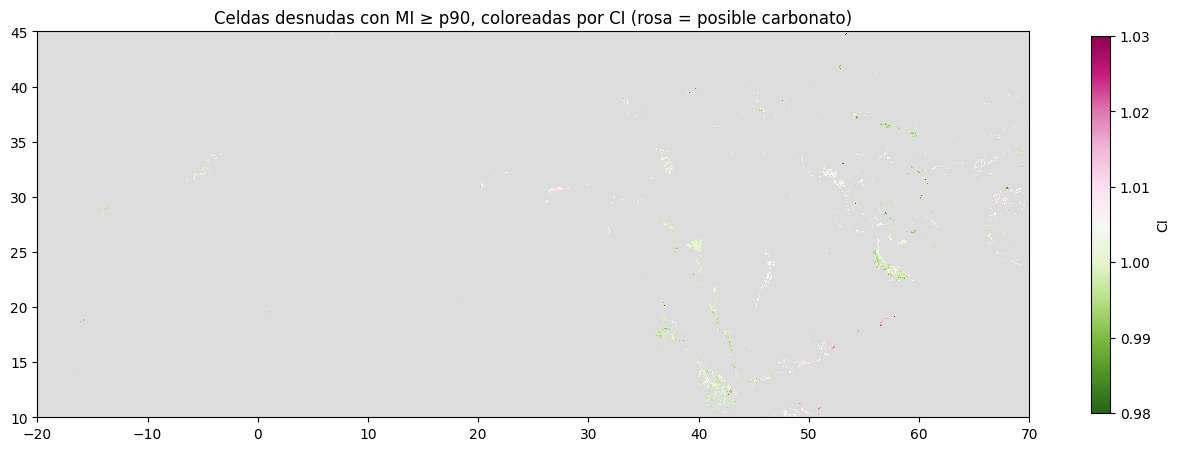

In [10]:
base = (~np.isnan(emis.MI.values)) & (np.nan_to_num(emis.nieve.values, nan=1) < UMBRAL_NIEVE)
desnudo_med = base & (ndvi_med.values > -0.02) & (ndvi_med.values < UMBRAL_DESNUDO)
p90_mi = np.percentile(emis.MI.values[desnudo_med], 90)
alto_mi = desnudo_med & (emis.MI.values >= p90_mi)
ci_alto = emis.CI.values[alto_mi]
ci_volc = puntos[puntos.tipo.isin(["analogo_luna", "volcanico_prueba"])].CI
print(f"Celdas desnudas (NDVI mediano): {desnudo_med.sum():,} | con MI ≥ p90 ({p90_mi:.3f}): {alto_mi.sum():,}")
print("CI en celdas con MI alto: p10 {:.3f} · mediana {:.3f} · p90 {:.3f}".format(*np.percentile(ci_alto, [10, 50, 90])),
      f"| volcánicos y análogos: {ci_volc.min():.3f}–{ci_volc.max():.3f}")
print(f"Se excluirían por carbonato (CI > {UMBRAL_CI}): {(ci_alto > UMBRAL_CI).mean()*100:.1f} % de las celdas con MI alto")

x0, x1, y0, y1 = -20, 70, 10, 45
j0, j1 = np.searchsorted(LONS, [x0, x1]); i0, i1 = np.searchsorted(LATS, [y0, y1])
fig, ax = plt.subplots(figsize=(16, 7))
im = ax.imshow(np.where(alto_mi, emis.CI.values, np.nan)[i0:i1, j0:j1], origin="lower", extent=[x0, x1, y0, y1],
               cmap="PiYG_r", vmin=0.98, vmax=1.03, interpolation="nearest")
ax.set_facecolor("#dddddd"); plt.colorbar(im, ax=ax, label="CI", shrink=0.7)
ax.set_title("Celdas desnudas con MI ≥ p90, coloreadas por CI (rosa = posible carbonato)"); plt.show()

## 5. Perfil Luna v0
- **Dominio**: celdas sin nieve en el verano de su hemisferio, con NDVI mediano entre −0,02 y 0,15 (ni agua ni vegetación) y CI ≤ 1,008 (no carbonato).
- **Puntuación**: percentil del MI dentro del dominio (0-100). Alto = superficie desnuda pobre en cuarzo, normalmente máfica (basalto).
- **Limitación**: un MI alto no es exclusivo del basalto (arcillas y otras rocas pobres en sílice también lo dan); el perfil detecta
  *superficies desnudas pobres en cuarzo y no carbonatadas*. La validación con análogos lunares dice si eso basta.

Celdas en el dominio: 1,026,699 (12.2 % de la tierra con dato)


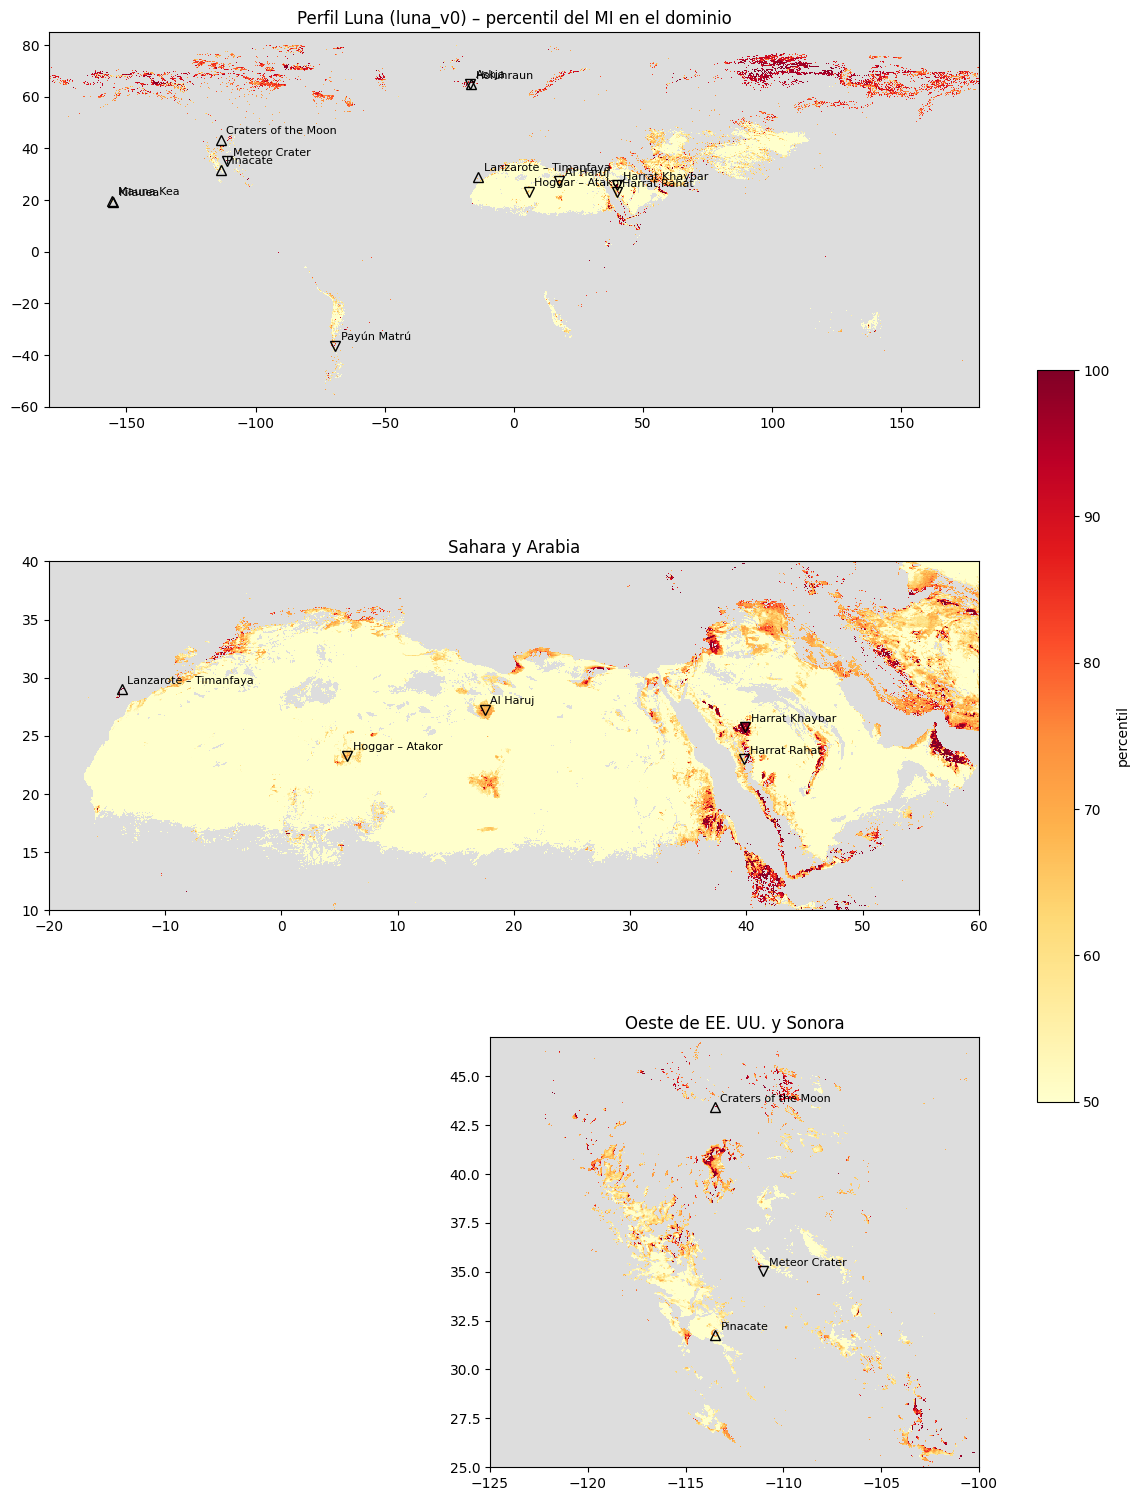

In [11]:
dominio = desnudo_med & (emis.CI.values <= UMBRAL_CI)
pct = np.full(emis.MI.shape, np.nan, dtype="float32")
pct[dominio] = pd.Series(emis.MI.values[dominio]).rank(pct=True).values * 100
indice_luna = xr.Dataset({
    "luna_pct": (("lat", "lon"), pct),
    "dominio": (("lat", "lon"), dominio.astype("int8")),
}, coords={"lat": LATS, "lon": LONS})
indice_luna["luna_pct"].attrs = {"units": "percentil", "long_name": "Percentil del MI dentro del dominio lunar"}
indice_luna.attrs = {"version": VERSION_LUNA, "MI": "e9.1/e10.6 (CAMEL)",
                     "dominio": f"nieve < {UMBRAL_NIEVE}, -0.02 < NDVI mediano < {UMBRAL_DESNUDO}, CI <= {UMBRAL_CI}"}
guardar_nc(indice_luna, f"{RES_LUNA}/indice_{VERSION_LUNA}.nc",
           {"luna_pct": {"dtype": "int16", "scale_factor": 0.01, "_FillValue": -32768, "zlib": True},
            "dominio": {"zlib": True}})
print(f"Celdas en el dominio: {dominio.sum():,} ({dominio.sum() / (~np.isnan(emis.MI.values)).sum() * 100:.1f} % de la tierra con dato)")

def mapa(ax, x0, x1, y0, y1, titulo):
    j0, j1 = np.searchsorted(LONS, [x0, x1]); i0, i1 = np.searchsorted(LATS, [y0, y1])
    im = ax.imshow(pct[i0:i1, j0:j1], origin="lower", extent=[x0, x1, y0, y1], cmap="YlOrRd",
                   vmin=50, vmax=100, interpolation="nearest")
    for r in ANALOGOS_LUNA.itertuples():
        if x0 <= r.lon <= x1 and y0 <= r.lat <= y1 and r.tipo in ("analogo_luna", "volcanico_prueba", "impacto"):
            ax.plot(r.lon, r.lat, "k^" if r.tipo == "analogo_luna" else "kv", ms=7, mfc="none")
            ax.annotate(r.nombre.split(",")[0], (r.lon, r.lat), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_facecolor("#dddddd"); ax.set_title(titulo)
    return im

fig, axes = plt.subplots(3, 1, figsize=(15, 19))
mapa(axes[0], -180, 180, -60, 85, f"Perfil Luna ({VERSION_LUNA}) – percentil del MI en el dominio")
mapa(axes[1], -20, 60, 10, 40, "Sahara y Arabia")
im = mapa(axes[2], -125, -100, 25, 47, "Oeste de EE. UU. y Sonora")
plt.colorbar(im, ax=axes, label="percentil", shrink=0.5); plt.show()

## 6. Validación
Para cada punto: ¿cae en el dominio? ¿Con qué percentil? Si su celda queda fuera (vegetación, nieve, carbonato),
se busca la celda válida más cercana a ≤ 25 km y se indica el motivo de la exclusión.

In [12]:
RADIO_BUSQUEDA_KM = 25

def motivo_exclusion(i, j):
    m = []
    if np.isnan(emis.MI.values[i, j]):                         m.append("sin dato de emisividad")
    if np.nan_to_num(emis.nieve.values[i, j], nan=1) >= UMBRAL_NIEVE: m.append("nieve")
    v = ndvi_med.values[i, j]
    if not (-0.02 < v < UMBRAL_DESNUDO):                       m.append(f"NDVI mediano {v:.2f}")
    if emis.CI.values[i, j] > UMBRAL_CI:                       m.append("carbonato (CI)")
    return ", ".join(m) or "—"

def evaluar(la, lo):
    i, j = celda(la, lo)
    if dominio[i, j]:
        return float(pct[i, j]), 0.0, "—"
    r = int(np.ceil(RADIO_BUSQUEDA_KM / 111 / DLAT)) + 1
    ii, jj = np.nonzero(dominio[max(i - r, 0):i + r + 1, max(j - r, 0):j + r + 1])
    if len(ii) == 0:
        return np.nan, np.nan, motivo_exclusion(i, j)
    ii, jj = ii + max(i - r, 0), jj + max(j - r, 0)
    d = haversine_km(la, lo, LATS[ii], LONS[jj])
    k = int(np.argmin(d))
    if d[k] > RADIO_BUSQUEDA_KM:
        return np.nan, np.nan, motivo_exclusion(i, j)
    return float(pct[ii[k], jj[k]]), float(d[k]), motivo_exclusion(i, j)

filas = []
for r in ANALOGOS_LUNA.itertuples():
    p, d, motivo = evaluar(r.lat, r.lon)
    filas.append({"nombre": r.nombre, "tipo": r.tipo, "verificacion": r.verificacion,
                  "percentil": round(p, 1) if not np.isnan(p) else np.nan,
                  "dist_celda_km": round(d, 1) if not np.isnan(d) else np.nan, "celda_propia_excluida_por": motivo})
validacion_luna = pd.DataFrame(filas)
validacion_luna.to_csv(f"{RES_LUNA}/validacion_{VERSION_LUNA}.csv", index=False)
display(validacion_luna)

grupos = validacion_luna.groupby("tipo").percentil
resumen_luna = pd.DataFrame({"n": validacion_luna.groupby("tipo").size(), "con_dato": grupos.count(),
                             "mediana": grupos.median().round(1), "minimo": grupos.min(), "maximo": grupos.max()})
display(resumen_luna)
an = validacion_luna[(validacion_luna.tipo == "analogo_luna") & (validacion_luna.verificacion == "verificada")].percentil.dropna()
neg = validacion_luna[validacion_luna.tipo.str.startswith("control")].percentil.dropna()
print(f"Análogos lunares verificados con dato: {len(an)} | mediana {an.median():.1f}")
print(f"Controles con dato: {len(neg)} | mediana {neg.median():.1f} | máximo {neg.max():.1f}")
print(f"Separación de medianas: {an.median() - neg.median():.1f} | peor análogo − mejor control: {an.min() - neg.max():.1f}")

,nombre,tipo,verificacion,percentil,dist_celda_km,celda_propia_excluida_por
0,"Craters of the Moon, Idaho",analogo_luna,verificada,95.9,3.7,NDVI mediano 0.27
1,"Kīlauea, Hawái",analogo_luna,verificada,33.3,6.1,NDVI mediano 0.48
2,"Pinacate, Sonora",analogo_luna,verificada,78.9,5.5,NDVI mediano 0.18
3,"Askja, Islandia",analogo_luna,verificada,90.8,19.3,NDVI mediano -0.03
4,Lanzarote – Timanfaya,analogo_luna,verificada,100.0,0.0,—
5,"Mauna Kea, Hawái",analogo_luna,pendiente,45.8,0.0,—
6,"Meteor Crater, Arizona",impacto,verificada,45.6,18.4,NDVI mediano 0.16
7,"Al Haruj, Libia",volcanico_prueba,,68.2,0.0,—
8,"Harrat Khaybar, Arabia Saudí",volcanico_prueba,,99.6,0.0,—
9,"Harrat Rahat, Arabia Saudí",volcanico_prueba,,68.9,0.0,—


,n,con_dato,mediana,minimo,maximo
tipo,,,,,
analogo_luna,6,6,84.8,33.3,100.0
control_arena,5,5,10.5,2.5,33.3
control_ciudad,6,0,NaN,NaN,NaN
impacto,1,1,45.6,45.6,45.6
volcanico_prueba,6,5,68.9,58.7,99.6


Análogos lunares verificados con dato: 5 | mediana 90.8
Controles con dato: 5 | mediana 10.5 | máximo 33.3
Separación de medianas: 80.3 | peor análogo − mejor control: 0.0


## 7. Regiones candidatas
Celdas ≥ p95 contiguas (8 vecinos), con un mínimo de 10 celdas (~250 km²). Se ordenan por **área**: a 5 km muchas celdas llegan al percentil 100,
así que el tamaño del campo es lo que distingue una región importante.

In [13]:
UMBRAL_PCT, MIN_CELDAS, N_REGIONES, RADIO_REGION_KM = 95, 10, 20, 50
KM_GRADO = 111.32

etiquetas, n = ndimage.label(np.nan_to_num(pct, nan=0) >= UMBRAL_PCT, structure=np.ones((3, 3)))
ids = np.arange(1, n + 1)
area_celda = (DLAT * KM_GRADO) * (DLON * KM_GRADO * np.cos(np.radians(LATS)))[:, None] * np.ones((1, len(LONS)))
n_celdas = ndimage.sum(np.ones_like(pct), etiquetas, ids)
areas = ndimage.sum(area_celda, etiquetas, ids)
medias = ndimage.mean(np.nan_to_num(pct), etiquetas, ids)
cent = ndimage.center_of_mass(np.ones_like(pct), etiquetas, ids)
reg = pd.DataFrame({"region_id": ids, "n_celdas": n_celdas.astype(int), "area_km2": areas.round(-1),
                    "percentil_medio": np.round(medias, 1),
                    "lat": [LATS[int(round(c[0]))] for c in cent], "lon": [LONS[int(round(c[1]))] for c in cent]})
reg = reg[reg.n_celdas >= MIN_CELDAS].sort_values("area_km2", ascending=False).head(N_REGIONES).reset_index(drop=True)
reg.insert(0, "rango", range(1, len(reg) + 1))

con_fuente = ANALOGOS_LUNA[ANALOGOS_LUNA.tipo.isin(["analogo_luna", "volcanico_prueba", "impacto"])]
mas_cercano, distancias, estados, fuentes = [], [], [], []
for r in reg.itertuples():
    ii, jj = np.nonzero(etiquetas == r.region_id)
    d = [haversine_km(a.lat, a.lon, LATS[ii], LONS[jj]).min() for a in con_fuente.itertuples()]
    k = int(np.argmin(d)); a = con_fuente.iloc[k]
    mas_cercano.append(a.nombre); distancias.append(round(float(d[k])))
    if d[k] > RADIO_REGION_KM:
        estados.append("No")
    elif a.tipo == "volcanico_prueba":
        estados.append("Campo volcánico (sin fuente lunar)")
    else:
        estados.append("Sí" if a.verificacion == "verificada" else "Pendiente")
    fuentes.append(a.fuente if d[k] <= RADIO_REGION_KM else "")
reg["referencia_mas_cercana"], reg["distancia_km"] = mas_cercano, distancias
reg["analogo_conocido"], reg["fuente"] = estados, fuentes
print(f"Regiones ≥ p{UMBRAL_PCT}: {n:,} en total | con ≥ {MIN_CELDAS} celdas: {(n_celdas >= MIN_CELDAS).sum():,}")

Regiones ≥ p95: 6,865 en total | con ≥ 10 celdas: 539


rango,region,area_km2,percentil_medio,n_celdas,analogo_conocido,referencia_mas_cercana,distancia_km,fuente
1,"Krai de Krasnoyarsk, Rusia",51310.0,98.3,5093,No,"Askja, Islandia",3942,
2,"Krai de Krasnoyarsk, Rusia",43630.0,97.3,3763,No,"Askja, Islandia",4073,
3,"República de Sajá, Rusia",25450.0,97.0,2326,No,"Askja, Islandia",4613,
4,"Batina Norte, Omán",21820.0,99.2,769,No,"Harrat Khaybar, Arabia Saudí",1603,
5,"República de Sajá, Rusia",19130.0,97.1,2052,No,"Askja, Islandia",4128,
6,"Krai de Krasnoyarsk, Rusia",17910.0,97.2,2004,No,"Askja, Islandia",3873,
7,"Yukón, Canadá",11360.0,98.2,873,No,"Craters of the Moon, Idaho",2716,
8,"Krai de Krasnoyarsk, Rusia",10230.0,97.1,1148,No,"Askja, Islandia",3753,
9,"República de Sajá, Rusia",8670.0,97.1,767,No,"Askja, Islandia",4731,
10,"Provincia de Medina, Arabia Saudita",8580.0,98.8,307,Campo volcánico (sin fuente lunar),"Harrat Khaybar, Arabia Saudí",4,


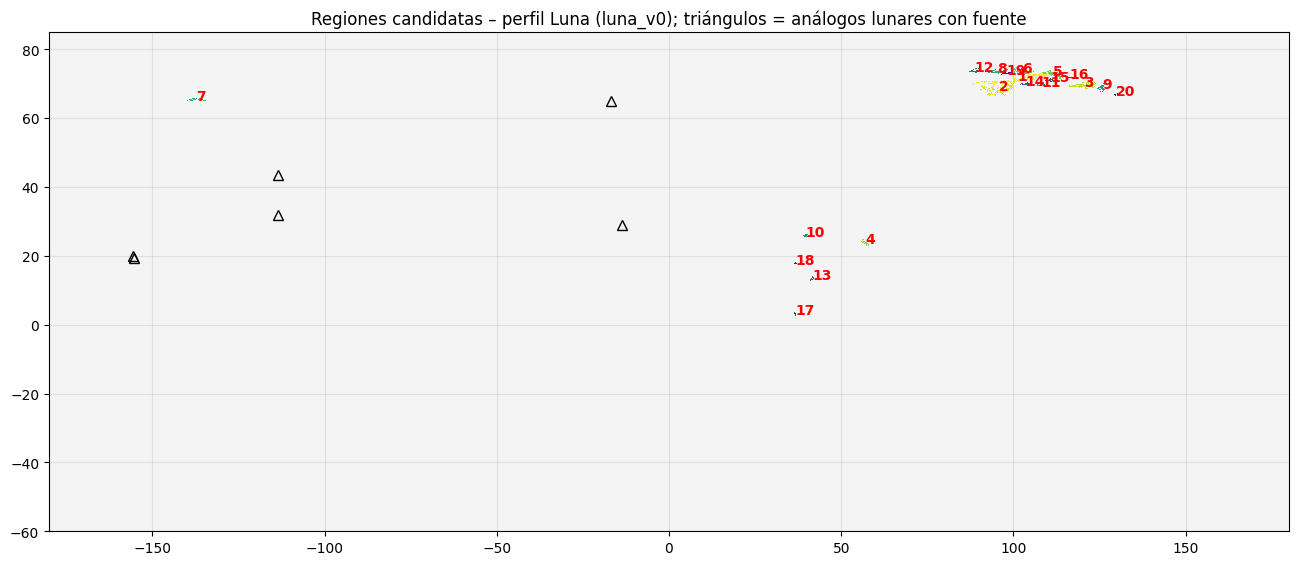

In [14]:
# Nombres de lugar (OpenStreetMap, con la misma caché que el EDA de Marte)
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
logging.getLogger("geopy").setLevel(logging.ERROR); logging.getLogger("urllib3").setLevel(logging.ERROR)
reverse = RateLimiter(Nominatim(user_agent="space-apps-2026-analogos", timeout=10).reverse,
                      min_delay_seconds=1.1, max_retries=2, error_wait_seconds=5, swallow_exceptions=False)
ruta_geo = f"{CACHE_API}/geocodificacion.csv"
geo_cache = (pd.read_csv(ruta_geo, keep_default_na=False).set_index("clave")["region"].to_dict()
             if os.path.exists(ruta_geo) else {})

def es_latino(txt):
    return all(ord(ch) < 0x250 or not ch.isalpha() for ch in txt)

def nombre_region(lat, lon):
    clave = f"{lat:.2f},{lon:.2f}"
    if clave not in geo_cache:
        try:
            loc = reverse((lat, lon), language="es", zoom=5)
        except Exception:
            return "error de geocodificación"
        if loc is None:
            geo_cache[clave] = "sin resultado (remoto)"
        else:
            a = loc.raw.get("address", {})
            geo_cache[clave] = ", ".join(p for p in [a.get("state") or a.get("region") or a.get("county"),
                                                     a.get("country")] if p) or loc.address
        pd.DataFrame({"clave": list(geo_cache), "region": list(geo_cache.values())}).to_csv(ruta_geo, index=False)
    partes = [p for p in geo_cache[clave].split(", ") if es_latino(p)]
    return ", ".join(partes) or geo_cache[clave]

reg["region"] = [nombre_region(la, lo) for la, lo in zip(reg.lat, reg.lon)]
reg.to_csv(f"{RES_LUNA}/regiones_{VERSION_LUNA}.csv", index=False)
display(HTML(reg[["rango", "region", "area_km2", "percentil_medio", "n_celdas", "analogo_conocido",
                  "referencia_mas_cercana", "distancia_km", "fuente"]].to_html(render_links=True, escape=False, index=False)))

rango_mapa = np.full(pct.shape, np.nan)
for r in reg.itertuples():
    rango_mapa[etiquetas == r.region_id] = r.rango
fig, ax = plt.subplots(figsize=(16, 7))
ax.imshow(rango_mapa, origin="lower", extent=[LONS[0], LONS[-1], LATS[0], LATS[-1]], cmap="viridis_r",
          interpolation="nearest")
for r in reg.itertuples():
    ax.annotate(str(r.rango), (r.lon, r.lat), color="red", fontweight="bold", fontsize=10)
for r in ANALOGOS_LUNA[ANALOGOS_LUNA.tipo == "analogo_luna"].itertuples():
    ax.plot(r.lon, r.lat, "k^", ms=7, mfc="none")
ax.set_xlim(-180, 180); ax.set_ylim(-60, 85); ax.grid(alpha=0.3); ax.set_facecolor("#f4f4f4")
ax.set_title(f"Regiones candidatas – perfil Luna ({VERSION_LUNA}); triángulos = análogos lunares con fuente"); plt.show()

## 8. Registro

In [15]:
registro_luna = {
    "fecha_ejecucion": datetime.datetime.now().isoformat(timespec="seconds"),
    "version": VERSION_LUNA,
    "datos": {"emisividad": "CAMEL CAM5K30EMCLIM v003, climatología 2003-2021; julio (norte) y enero (sur)",
              "vegetacion": "VIIRS VNP13C2 v002 2023, NDVI mediano anual"},
    "indices": {"MI": "e9.1/e10.6", "QI": "e8.6^2/(e8.3*e9.1)", "CI": "e10.6/e11.3",
                "referencia": "adaptados de Ninomiya (índices ASTER TIR); Corrie, Ninomiya y Aitchison (2010)"},
    "dominio": {"nieve_max": UMBRAL_NIEVE, "ndvi_mediano": [-0.02, UMBRAL_DESNUDO], "CI_max": UMBRAL_CI},
    "puntuacion": "percentil del MI dentro del dominio",
    "regiones": {"umbral_percentil": UMBRAL_PCT, "min_celdas": MIN_CELDAS, "orden": "área",
                 "radio_analogo_km": RADIO_REGION_KM},
    "validacion": {"resumen": resumen_luna.reset_index().to_dict("records"),
                   "separacion_medianas": float(an.median() - neg.median()),
                   "peor_analogo_menos_mejor_control": float(an.min() - neg.max())},
    "limitaciones": ["MI alto no es exclusivo del basalto", "celdas de ~5 km mezclan coladas con otros terrenos",
                     "coordenadas de los puntos de referencia aproximadas"],
}
with open(f"{RES_LUNA}/registro_{VERSION_LUNA}.json", "w", encoding="utf-8") as f:
    json.dump(registro_luna, f, ensure_ascii=False, indent=2, default=float)
for n_ in sorted(os.listdir(RES_LUNA)):
    print(f"  {n_:40s} {os.path.getsize(f'{RES_LUNA}/{n_}')/1e6:8.2f} MB")

  indice_luna_v0.nc                            2.01 MB
  puntos_referencia_luna.csv                   0.00 MB
  regiones_luna_v0.csv                         0.00 MB
  registro_luna_v0.json                        0.00 MB
  validacion_luna_v0.csv                       0.00 MB


## 9. Conclusiones
*Rellenar tras la primera ejecución con los números de las secciones 4 a 7.*